# Investigación y decisiones comerciales

Lectura de datos comerciales, calidad, segmentación y forecast. Las fuentes y fórmulas están documentadas en `docs/ingenieria_caracteristicas.md`.

In [1]:
from pathlib import Path
import pandas as pd
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'src' / 'pipeline.py').is_file(), 'Abre Jupyter desde la raíz o notebooks/'


## 1. Controles del origen

In [2]:
import sys
sys.path.insert(0,str(ROOT/'src'))
from pipeline import load, analyse_sales, interval_quality
from analitica import calendario_ventas, resumen_comercial, clasificacion_xyz, clasificacion_abc, cobertura_temporal, agregar_cobertura, presupuesto_muestra, backtesting
sales,stock=load()
qa=analyse_sales(sales); display(qa)


,control,value,unit
0,filas_ventas,125751,registros
1,duplicados_clave_ventas,0,registros
2,devoluciones_filas,7491,registros
3,devoluciones_cantidad_no_negativa,0,registros
4,devoluciones_venta_no_negativa,0,registros
5,devoluciones_cogs_no_negativo,0,registros
6,razon_devolucion_filas_no_nulas,0,registros
7,ventas_brutas,11215681.26,importe
8,importe_devoluciones,-733571.01,importe
9,ventas_netas,10482110.25,importe


## 2. Venta y margen por división

In [3]:
ventas=calendario_ventas(sales)
divisiones=resumen_comercial(ventas,['Product Division'])
divisiones


,Product Division,ventas_netas,costo_ventas,margen_bruto,unidades_netas,unidades_brutas,unidades_devueltas,transacciones_reportadas,margen_pct
0,Femme Footwear,2712206.85,1.638865e+06,1.073342e+06,25876.0,28198.0,2322.0,30353,39.574487
1,Junior Apparel,431713.95,2.545831e+05,1.771308e+05,18348.0,18979.0,631.0,19301,41.029668
2,Scholar Footwear,7338189.45,3.954303e+06,3.383886e+06,72771.0,77365.0,4594.0,81466,46.113369


## 3. Portafolio ABC–XYZ

In [4]:
productos=clasificacion_xyz(ventas,clasificacion_abc(ventas))
productos['abc_ventas'].value_counts().sort_index()


abc_ventas
A    929
B    601
C    796
Name: count, dtype: int64

In [5]:
pd.crosstab(productos['abc_ventas'], productos['xyz_demanda'])

xyz_demanda,X,Y,Z
abc_ventas,,,
A,8,292,629
B,2,65,534
C,2,53,741


La clasificación X/Y/Z describe variabilidad de unidades vendidas, no demanda potencial ni ausencia de stock.

In [6]:
productos.nlargest(10, 'ventas_netas')[['Product No','ventas_netas','margen_pct','abc_xyz']]

,Product No,ventas_netas,margen_pct,abc_xyz
0,PROD-140871,104027.50,55.215842,AZ
1,PROD-100805,102481.99,48.011304,AY
2,PROD-100804,72822.50,47.861114,AY
3,PROD-100803,71496.48,48.037778,AY
4,PROD-140870,61705.00,54.978754,AY
5,PROD-175338,60040.00,49.400000,AZ
6,PROD-100802,56361.50,48.295893,AY
7,PROD-140869,55251.90,55.539502,AZ
8,PROD-175334,51110.00,49.400000,AZ
9,PROD-152143,45672.00,49.508539,AZ


## 4. Tipos de venta y margen bruto

In [7]:
tipos=resumen_comercial(ventas,['Sales Type'])
tipos


,Sales Type,ventas_netas,costo_ventas,margen_bruto,unidades_netas,unidades_brutas,unidades_devueltas,transacciones_reportadas,margen_pct
0,Clearance,17408.76,3.109033e+04,-1.368157e+04,1499.0,1525.0,26.0,1448,-78.590147
1,Full Price,8896456.66,4.601570e+06,4.294887e+06,87259.0,93235.0,5976.0,98697,48.276375
2,Markdown Tier 1,177712.44,1.649612e+05,1.275119e+04,4025.0,4268.0,243.0,4463,7.175181
3,Markdown Tier 2,77602.53,8.766106e+04,-1.005853e+04,2367.0,2461.0,94.0,2484,-12.961601
4,Promo,1312929.86,9.624686e+05,3.504613e+05,21845.0,23053.0,1208.0,24028,26.693069


En esta muestra, Markdown Tier 2 y Clearance registran márgenes negativos. El costo Cogs procede de la fuente, sin especificación de su política contable.

## 5. Cobertura temporal de inventario

In [8]:
cruces=cobertura_temporal(ventas,stock)
cobertura=cruces.groupby('estado_cobertura').agg(filas=('id_venta','size'),importe=('Sales Amount','sum'))
cobertura


,filas,importe
estado_cobertura,,
SIN_DATO,33160,3190352.07
STOCK_CERO,10581,1083294.56
STOCK_NEGATIVO,878,66661.34
STOCK_POSITIVO,81132,6141802.28


In [9]:
agregar_cobertura(cruces,['Product Division'])


,Product Division,filas_ventas,ventas_netas,filas_sin_dato,ventas_sin_dato,ventas_con_dato,filas_sin_dato_pct,ventas_sin_dato_pct
0,Femme Footwear,29848,2712206.85,10207,1055881.12,1656325.73,34.196596,38.930700
1,Junior Apparel,18996,431713.95,5408,138392.98,293320.97,28.469151,32.056638
2,Scholar Footwear,76907,7338189.45,17545,1996077.97,5342111.48,22.813268,27.201232


La ausencia de un intervalo vigente es una condición de registro. Conviene analizar por separado ausencia histórica, vigencia anterior y huecos entre intervalos.

`SIN_DATO` indica ausencia de intervalo vigente: no debe representarse como stock cero.

## 6. Presupuesto de muestra

In [10]:
presupuesto=presupuesto_muestra(ventas)
presupuesto.groupby('mes')[['meta_escenario','ventas_netas']].sum()


,meta_escenario,ventas_netas
mes,,
2025-07,741986.16,855566.55
2025-08,898318.61,1535128.70
2025-09,1612047.87,860467.22
2025-10,903490.60,821268.57
2025-11,862413.90,871931.35
2025-12,915543.69,1785519.94
2026-01,1873864.38,565247.84
2026-02,593510.24,1038930.89
2026-03,1090835.43,934134.77


Los objetivos se construyen con la venta del mes previo y un incremento supuesto del 5 %. Solo se utilizan meses completos.

## 7. Forecast semanal y prueba temporal

In [11]:
serie,detalle,evaluacion,por_corte,prueba,futuro=backtesting(ventas)
display(evaluacion)
display(por_corte.loc[por_corte["modelo"].eq(evaluacion.iloc[0]["modelo"])])

,modelo,mae,error_abs_total,real_abs_total,sesgo,cortes,wape_pct
4,ultimo_valor,91421.498500,1.828430e+06,4820194.63,23182.117500,5,37.932700
2,media_total,101424.925519,2.028499e+06,4820194.63,15342.041266,5,42.083332
1,media_8,116839.818500,2.336796e+06,4820194.63,7131.159750,5,48.479295
0,media_4,136893.662500,2.737873e+06,4820194.63,19447.150000,5,56.800056
3,patron_4,150440.518000,3.008810e+06,4820194.63,19447.150000,5,62.420931


,modelo,origen,error_absoluto,observado,sesgo_semanal,wape_pct
20,ultimo_valor,2025-10-19,113286.14,660149.06,-28321.5350,17.160691
21,ultimo_valor,2025-11-16,450018.27,1119509.03,112504.5675,40.197824
22,ultimo_valor,2025-12-14,728092.25,1368447.59,-96412.0425,53.205710
23,ultimo_valor,2026-01-11,72285.66,528278.10,11952.6850,13.683259
24,ultimo_valor,2026-02-08,464747.65,1143810.85,116186.9125,40.631513


In [12]:
prueba


,semana_fin,real,pronostico,modelo,error,error_absoluto
0,2026-03-29,169130.77,201141.35,ultimo_valor,-32010.58,32010.58
1,2026-04-05,203918.87,201141.35,ultimo_valor,2777.52,2777.52
2,2026-04-12,145253.39,201141.35,ultimo_valor,-55887.96,55887.96
3,2026-04-19,123103.68,201141.35,ultimo_valor,-78037.67,78037.67


In [13]:
futuro


,semana_fin,pronostico,modelo,tipo
0,2026-05-03,123103.68,ultimo_valor,LINEA_BASE_EXPLORATORIA
1,2026-05-10,123103.68,ultimo_valor,LINEA_BASE_EXPLORATORIA
2,2026-05-17,123103.68,ultimo_valor,LINEA_BASE_EXPLORATORIA
3,2026-05-24,123103.68,ultimo_valor,LINEA_BASE_EXPLORATORIA
4,2026-05-31,123103.68,ultimo_valor,LINEA_BASE_EXPLORATORIA
5,2026-06-07,123103.68,ultimo_valor,LINEA_BASE_EXPLORATORIA
6,2026-06-14,123103.68,ultimo_valor,LINEA_BASE_EXPLORATORIA
7,2026-06-21,123103.68,ultimo_valor,LINEA_BASE_EXPLORATORIA


La línea de predicción no constituye un intervalo de confianza. El desempeño fuera de muestra determina el alcance de las conclusiones.

El WAPE varía entre cortes y limita el uso de la proyección como referencia de decisión. La semana parcial se omite de la serie semanal completa.

## 8. Evolución visual de la serie

In [14]:
import matplotlib.pyplot as plt
serie['semana_fin']=pd.to_datetime(serie['semana_fin'])
futuro['semana_fin']=pd.to_datetime(futuro['semana_fin'])


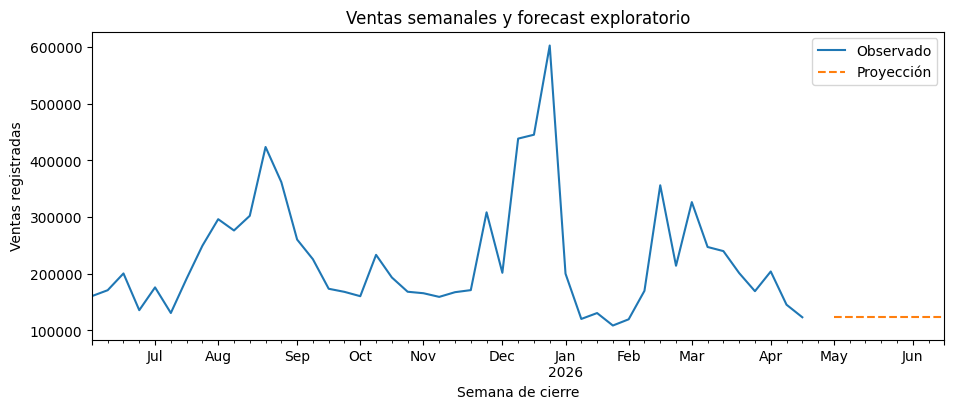

In [15]:
ax = serie.plot(x='semana_fin', y='ventas_observadas', figsize=(11,4), label='Observado')
futuro.plot(x='semana_fin', y='pronostico', ax=ax, style='--', label='Proyección')
ax.set(xlabel='Semana de cierre', ylabel='Ventas registradas', title='Ventas semanales y forecast exploratorio')
plt.show()